In [1]:
import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("GPU not detected")

PyTorch version: 2.14.1+cu130
CUDA available: True
GPU: Tesla T4


In [2]:
from google.colab import files

uploaded = files.upload()

Saving ResDerainNet-master.zip to ResDerainNet-master.zip


In [3]:
import zipfile
import os

zip_path = "ResDerainNet-master.zip"

with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall("/content/")

project_path = "/content/ResDerainNet-master"

print("Repository extracted successfully!")
print("\nFiles:")
for root, dirs, files_list in os.walk(project_path):
    for file in files_list:
        print(os.path.relpath(os.path.join(root, file), project_path))

Repository extracted successfully!

Files:
Residual_net_relu_matlab_fast.prototxt
README.md
demo_fast_derain.m
demo_synthesize.m
demo_derain.m
Residual_net_relu_matlab.prototxt
output_rain_noise.m
image/real_world/3.jpg
image/real_world/2.jpg
image/real_world/4.jpg
image/real_world/5.jpg
image/real_world/6.jpg
image/real_world/1.jpg
image/synthetic/3original.jpg
image/synthetic/1original.jpg
image/synthetic/4rain.bmp
image/synthetic/1rain.bmp
image/synthetic/4derained.bmp
image/synthetic/2rain.bmp
image/synthetic/2derained.bmp
image/synthetic/2original.jpg
image/synthetic/4original.jpg
image/synthetic/3derained.bmp
image/synthetic/3rain.bmp
image/synthetic/1derained.bmp
weight_add_residual/ResDerainNet_iter_100000.caffemodel.h5


In [6]:
import os

weight_path = (
    "/content/ResDerainNet-master/"
    "weight_add_residual/ResDerainNet_iter_100000.caffemodel.h5"
)

if os.path.exists(weight_path):
    print("Pretrained weights found!")
    print("File size:", round(os.path.getsize(weight_path) / (1024**2), 2), "MB")
else:
    print("Pretrained weights NOT found.")

Pretrained weights found!
File size: 2.68 MB


In [7]:
project_path = "/content/ResDerainNet-master"

proto_path = project_path + "/Residual_net_relu_matlab.prototxt"

with open(proto_path, "r") as f:
    architecture = f.read()

print(architecture[:10000])

name: "Res_DerainNet"
layer {
  name: "data"
  type: "Input"
  top: "rainy"
  #top: "rain_noise"
  input_param {
    shape: { dim: 1 dim: 3 dim: 128 dim: 128 }
  }
  include: { phase: TEST }
}


#1st_layer#########################
layer {
  name: "conv1"
  type: "Convolution"
  bottom: "rainy"
  top: "conv1"
  convolution_param {
    num_output: 64
    kernel_size: 3
    stride: 1
    pad: 1#0
    weight_filler {
      type: "msra"
      std: 0.001
    }
    bias_filler {
      type: "constant"
      value: 0
    }
  }
}
##ReLU_layer
layer {
  name: "relu1"
  type: "ReLU"
  bottom: "conv1"
  top: "relu1"
}
#2nd_layer###########################
layer {
  name: "conv2"
  type: "Convolution"
  bottom: "relu1"
  top: "conv2"
  convolution_param {
    num_output: 64
    kernel_size: 3
    stride: 1
    pad: 1#0
    weight_filler {
      type: "msra"
      std: 0.001
    }
    bias_filler {
      type: "constant"
      value: 0
    }
  }
}

##Batch Normalization
layer {
  name: "conv2-bn"
  

In [8]:
import re

with open(proto_path, "r") as f:
    architecture = f.read()

conv_layers = re.findall(
    r'name:\s*"(conv\d+)"\s*\n\s*type:\s*"Convolution"',
    architecture
)

print("Total convolution layers:", len(conv_layers))
print("Convolution layer names:")
print(conv_layers)

print("\nLast 1000 characters of architecture:")
print(architecture[-1000:])

Total convolution layers: 20
Convolution layer names:
['conv1', 'conv2', 'conv3', 'conv4', 'conv5', 'conv6', 'conv7', 'conv8', 'conv9', 'conv10', 'conv11', 'conv12', 'conv13', 'conv14', 'conv15', 'conv16', 'conv17', 'conv18', 'conv19', 'conv20']

Last 1000 characters of architecture:
r_mult: 0
    decay_mult: 0
  }
  param {
    lr_mult: 0
    decay_mult: 0
  }
  param {
    lr_mult: 0
    decay_mult: 0
  }
  batch_norm_param {
    moving_average_fraction: 0.99
    eps: 1e-8
  }
}
layer {
  name: "conv19-bn-scale"
  type: "Scale"
  bottom: "conv19"
  top: "conv19"
  param {
    lr_mult: 1
    decay_mult: 0
  }
  param {
    lr_mult: 1
    decay_mult: 1
  }
  scale_param {
    axis: 1
    num_axes: 1
    filler {
      type: "constant"
      value: 1
    }
    bias_term: true
    bias_filler {
      type: "constant"
      value: 0
    }
  }
}  
##ReLU_layer
layer {
  name: "relu19"
  type: "ReLU"
  bottom: "conv19"
  top: "relu19"
}

#last_layer############################
layer {
  nam

In [9]:
import h5py

weight_path = (
    "/content/ResDerainNet-master/"
    "weight_add_residual/ResDerainNet_iter_100000.caffemodel.h5"
)

with h5py.File(weight_path, "r") as f:
    def show_structure(name, obj):
        if isinstance(obj, h5py.Dataset):
            print(name, obj.shape)

    f.visititems(show_structure)

data/conv1/0 (64, 3, 3, 3)
data/conv1/1 (64,)
data/conv10/0 (64, 64, 3, 3)
data/conv10/1 (64,)
data/conv10-bn/0 (64,)
data/conv10-bn/1 (64,)
data/conv10-bn/2 (1,)
data/conv10-bn-scale/0 (64,)
data/conv10-bn-scale/1 (64,)
data/conv11/0 (64, 64, 3, 3)
data/conv11/1 (64,)
data/conv11-bn/0 (64,)
data/conv11-bn/1 (64,)
data/conv11-bn/2 (1,)
data/conv11-bn-scale/0 (64,)
data/conv11-bn-scale/1 (64,)
data/conv12/0 (64, 64, 3, 3)
data/conv12/1 (64,)
data/conv12-bn/0 (64,)
data/conv12-bn/1 (64,)
data/conv12-bn/2 (1,)
data/conv12-bn-scale/0 (64,)
data/conv12-bn-scale/1 (64,)
data/conv13/0 (64, 64, 3, 3)
data/conv13/1 (64,)
data/conv13-bn/0 (64,)
data/conv13-bn/1 (64,)
data/conv13-bn/2 (1,)
data/conv13-bn-scale/0 (64,)
data/conv13-bn-scale/1 (64,)
data/conv14/0 (64, 64, 3, 3)
data/conv14/1 (64,)
data/conv14-bn/0 (64,)
data/conv14-bn/1 (64,)
data/conv14-bn/2 (1,)
data/conv14-bn-scale/0 (64,)
data/conv14-bn-scale/1 (64,)
data/conv15/0 (64, 64, 3, 3)
data/conv15/1 (64,)
data/conv15-bn/0 (64,)
data/co

In [10]:
import h5py

with h5py.File(weight_path, "r") as f:
    for i in [2, 3, 10, 19]:
        group = f[f"data/conv{i}-bn"]

        mean = group["0"][:]
        variance = group["1"][:]
        factor = group["2"][:]

        print(f"\nconv{i}-bn")
        print("Mean shape:", mean.shape)
        print("Variance shape:", variance.shape)
        print("Scale factor:", factor)


conv2-bn
Mean shape: (64,)
Variance shape: (64,)
Scale factor: [99.99972]

conv3-bn
Mean shape: (64,)
Variance shape: (64,)
Scale factor: [99.99972]

conv10-bn
Mean shape: (64,)
Variance shape: (64,)
Scale factor: [99.99972]

conv19-bn
Mean shape: (64,)
Variance shape: (64,)
Scale factor: [99.99972]


In [11]:
import h5py
import numpy as np

with h5py.File(weight_path, "r") as f:
    for i in [2, 3, 10, 19]:
        group = f[f"data/conv{i}-bn"]
        print(f"\nconv{i}-bn")
        print("Mean:", group["0"][:5])
        print("Variance:", group["1"][:5])
        print("Factor:", group["2"][:])


conv2-bn
Mean: [ 29.427855    7.7980056 -10.948043   10.172124  -17.342907 ]
Variance: [9.365668  1.6133271 4.7899895 2.4140036 6.48668  ]
Factor: [99.99972]

conv3-bn
Mean: [  2.4112997  -12.083941    -6.6535997    1.089553    -0.94369745]
Variance: [1.4743897 1.2053723 0.7348048 1.0210547 0.5319641]
Factor: [99.99972]

conv10-bn
Mean: [-8.790275  -6.198249  -1.7963555 -4.538512  -3.4992366]
Variance: [1.551268   0.9212199  0.5056618  2.9483142  0.45106423]
Factor: [99.99972]

conv19-bn
Mean: [-11.919681   18.648064   -6.7051077  -3.6267383  -8.113409 ]
Variance: [1.9140407  0.92002195 0.9164341  0.54243344 1.8358189 ]
Factor: [99.99972]


In [12]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np
import h5py
import os

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using:", device)

Using: cuda


In [13]:
class ResDerainNet(nn.Module):
    def __init__(self):
        super().__init__()

        self.conv1 = nn.Conv2d(3, 64, 3, padding=1)

        self.convs = nn.ModuleList([
            nn.Conv2d(64, 64, 3, padding=1)
            for _ in range(18)
        ])

        self.bns = nn.ModuleList([
            nn.BatchNorm2d(64, eps=1e-8)
            for _ in range(18)
        ])

        self.conv20 = nn.Conv2d(64, 3, 3, padding=1)

    def forward(self, x):
        x = F.relu(self.conv1(x))

        for conv, bn in zip(self.convs, self.bns):
            x = F.relu(bn(conv(x)))

        return self.conv20(x)

In [14]:
model = ResDerainNet().to(device)
model.eval()

print(model)
print("\nTotal parameters:",
      sum(p.numel() for p in model.parameters()))

ResDerainNet(
  (conv1): Conv2d(3, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (convs): ModuleList(
    (0-17): 18 x Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  )
  (bns): ModuleList(
    (0-17): 18 x BatchNorm2d(64, eps=1e-08, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  )
  (conv20): Conv2d(64, 3, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
)

Total parameters: 670531


In [15]:
with h5py.File(weight_path, "r") as f:
    for i in range(1, 21):
        layer = getattr(model, f"conv{i}")

        weights = f[f"data/conv{i}/0"][:]
        bias = f[f"data/conv{i}/1"][:]

        layer.weight.data.copy_(
            torch.tensor(weights, dtype=torch.float32)
        )
        layer.bias.data.copy_(
            torch.tensor(bias, dtype=torch.float32)
        )

print("All 20 convolution layers loaded!")

AttributeError: 'ResDerainNet' object has no attribute 'conv2'

In [16]:
with h5py.File(weight_path, "r") as f:

    # Load first convolution
    model.conv1.weight.data.copy_(
        torch.tensor(f["data/conv1/0"][:], dtype=torch.float32)
    )
    model.conv1.bias.data.copy_(
        torch.tensor(f["data/conv1/1"][:], dtype=torch.float32)
    )

    # Load intermediate convolutions: conv2 to conv19
    for i in range(2, 20):
        layer = model.convs[i - 2]

        layer.weight.data.copy_(
            torch.tensor(f[f"data/conv{i}/0"][:], dtype=torch.float32)
        )
        layer.bias.data.copy_(
            torch.tensor(f[f"data/conv{i}/1"][:], dtype=torch.float32)
        )

    # Load final convolution
    model.conv20.weight.data.copy_(
        torch.tensor(f["data/conv20/0"][:], dtype=torch.float32)
    )
    model.conv20.bias.data.copy_(
        torch.tensor(f["data/conv20/1"][:], dtype=torch.float32)
    )

print("All 20 convolution layers loaded successfully!")

All 20 convolution layers loaded successfully!


In [17]:
model.eval()

print("Model loaded:", isinstance(model, ResDerainNet))
print("Device:", next(model.parameters()).device)
print("Convolution layers:", 20)
print("BatchNorm layers:", len(model.bns))

Model loaded: True
Device: cuda:0
Convolution layers: 20
BatchNorm layers: 18


In [18]:
from PIL import Image
import matplotlib.pyplot as plt
import numpy as np
import os

image_dir = "/content/ResDerainNet-master/image/synthetic"

rainy_path = os.path.join(image_dir, "2rain.bmp")
clean_path = os.path.join(image_dir, "2original.jpg")

rainy_img = np.array(Image.open(rainy_path).convert("RGB")).astype(np.float32) / 255.0
clean_img = np.array(Image.open(clean_path).convert("RGB")).astype(np.float32) / 255.0

print("Rainy image shape:", rainy_img.shape)
print("Ground truth shape:", clean_img.shape)

Rainy image shape: (480, 576, 3)
Ground truth shape: (480, 576, 3)


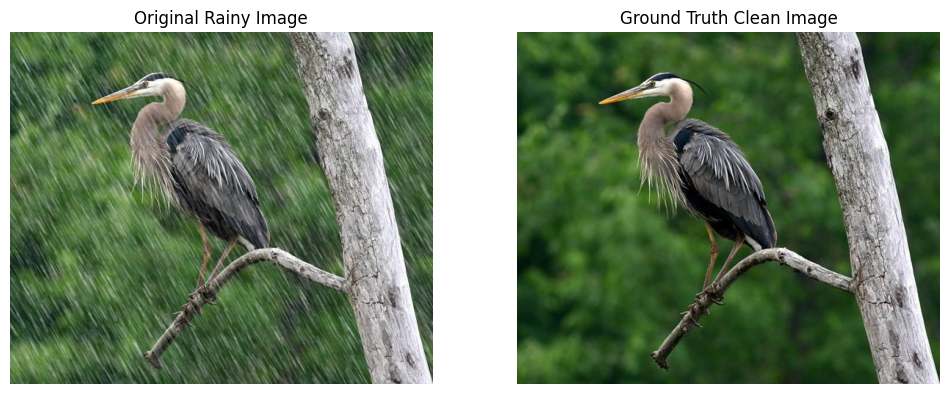

In [19]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.imshow(rainy_img)
plt.title("Original Rainy Image")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(clean_img)
plt.title("Ground Truth Clean Image")
plt.axis("off")

plt.show()

In [20]:
def get_patch_positions(length, patch_size=128, stride=106):
    positions = list(range(0, length, stride))

    for i in range(len(positions)):
        if positions[i] + patch_size > length:
            positions[i] = length - patch_size

    return sorted(set(positions))

print("Vertical positions:", get_patch_positions(rainy_img.shape[0]))
print("Horizontal positions:", get_patch_positions(rainy_img.shape[1]))

Vertical positions: [0, 106, 212, 318, 352]
Horizontal positions: [0, 106, 212, 318, 424, 448]


In [21]:
def predict_rain_patch(patch):
    # RGB HWC to NCHW
    tensor = torch.from_numpy(
        patch.transpose(2, 0, 1)
    ).unsqueeze(0).float().to(device)

    with torch.no_grad():
        prediction = model(tensor)

    # NCHW to HWC
    return prediction.squeeze(0).cpu().numpy().transpose(1, 2, 0)

In [22]:
def derain_image(image, patch_size=128, stride=106):
    height, width, channels = image.shape

    residual_sum = np.zeros_like(image)
    overlap_count = np.zeros((height, width, 1), dtype=np.float32)

    ys = get_patch_positions(height, patch_size, stride)
    xs = get_patch_positions(width, patch_size, stride)

    for y in ys:
        for x in xs:
            patch = image[y:y+patch_size, x:x+patch_size, :]

            rain_patch = predict_rain_patch(patch)

            residual_sum[y:y+patch_size, x:x+patch_size, :] += rain_patch
            overlap_count[y:y+patch_size, x:x+patch_size, :] += 1

    estimated_rain = residual_sum / np.maximum(overlap_count, 1)
    restored = np.clip(image - estimated_rain, 0, 1)

    return estimated_rain, restored

estimated_rain, restored_img = derain_image(rainy_img)

print("Deraining completed!")
print("Output shape:", restored_img.shape)

Deraining completed!
Output shape: (480, 576, 3)


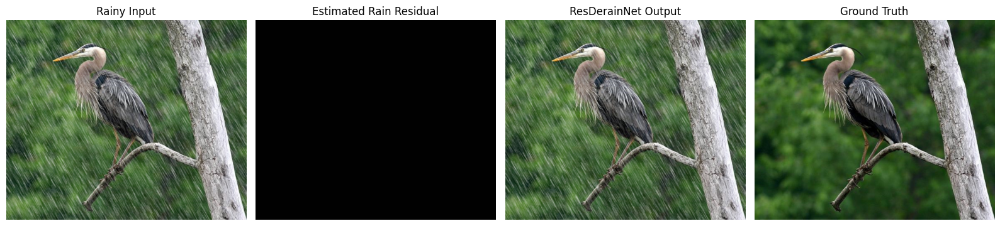

In [23]:
plt.figure(figsize=(16, 5))

images = [
    (rainy_img, "Rainy Input"),
    (estimated_rain, "Estimated Rain Residual"),
    (restored_img, "ResDerainNet Output"),
    (clean_img, "Ground Truth")
]

for i, (img, title) in enumerate(images):
    plt.subplot(1, 4, i + 1)
    plt.imshow(np.clip(img, 0, 1))
    plt.title(title)
    plt.axis("off")

plt.tight_layout()
plt.show()

In [24]:
!pip -q install scikit-image

In [25]:
from skimage.metrics import peak_signal_noise_ratio

psnr_rainy = peak_signal_noise_ratio(clean_img, rainy_img, data_range=1.0)
psnr_restored = peak_signal_noise_ratio(clean_img, restored_img, data_range=1.0)

print("PSNR before deraining:", round(psnr_rainy, 4), "dB")
print("PSNR after deraining:", round(psnr_restored, 4), "dB")
print("PSNR improvement:", round(psnr_restored - psnr_rainy, 4), "dB")

PSNR before deraining: 18.3723 dB
PSNR after deraining: 18.6556 dB
PSNR improvement: 0.2833 dB


In [26]:
from skimage.metrics import structural_similarity

ssim_rainy = structural_similarity(
    clean_img, rainy_img, channel_axis=2, data_range=1.0
)

ssim_restored = structural_similarity(
    clean_img, restored_img, channel_axis=2, data_range=1.0
)

print("SSIM before deraining:", round(ssim_rainy, 4))
print("SSIM after deraining:", round(ssim_restored, 4))
print("SSIM improvement:", round(ssim_restored - ssim_rainy, 4))

SSIM before deraining: 0.471
SSIM after deraining: 0.4728
SSIM improvement: 0.0019


In [27]:
from PIL import Image

output_dir = "/content/ResDerainNet_Results"
os.makedirs(output_dir, exist_ok=True)

Image.fromarray(
    (np.clip(restored_img, 0, 1) * 255).astype(np.uint8)
).save(output_dir + "/restored_image.png")

Image.fromarray(
    (np.clip(estimated_rain, 0, 1) * 255).astype(np.uint8)
).save(output_dir + "/estimated_rain.png")

print("Images saved in:", output_dir)

Images saved in: /content/ResDerainNet_Results


In [28]:
import pandas as pd

metrics = pd.DataFrame({
    "Metric": ["PSNR (dB)", "SSIM"],
    "Rainy Input": [psnr_rainy, ssim_rainy],
    "Restored Output": [psnr_restored, ssim_restored]
})

display(metrics)

metrics.to_csv(output_dir + "/evaluation_metrics.csv", index=False)
print("Metrics saved!")

,Metric,Rainy Input,Restored Output
0,PSNR (dB),18.372304,18.65557
1,SSIM,0.470972,0.47284


Metrics saved!


In [29]:
official_path = os.path.join(image_dir, "2derained.bmp")

official_img = np.array(
    Image.open(official_path).convert("RGB")
).astype(np.float32) / 255.0

print("Our output:", restored_img.shape)
print("Official output:", official_img.shape)
print("Ground truth:", clean_img.shape)

Our output: (480, 576, 3)
Official output: (480, 576, 3)
Ground truth: (480, 576, 3)


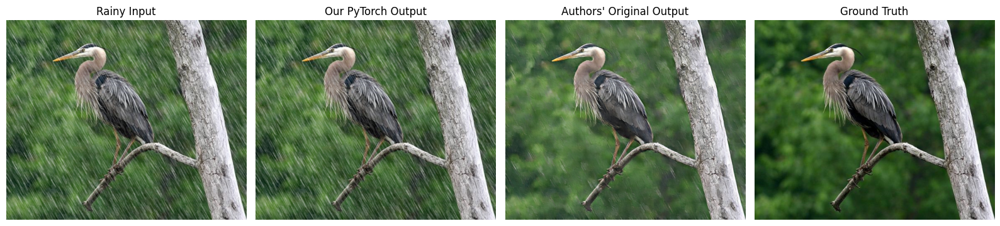

In [30]:
plt.figure(figsize=(16, 5))

comparison = [
    (rainy_img, "Rainy Input"),
    (restored_img, "Our PyTorch Output"),
    (official_img, "Authors' Original Output"),
    (clean_img, "Ground Truth")
]

for i, (img, title) in enumerate(comparison):
    plt.subplot(1, 4, i + 1)
    plt.imshow(np.clip(img, 0, 1))
    plt.title(title)
    plt.axis("off")

plt.tight_layout()
plt.show()

In [31]:
from skimage.metrics import mean_squared_error

mse_official = mean_squared_error(official_img, restored_img)
mae_official = np.mean(np.abs(official_img - restored_img))

print("MSE vs official output:", mse_official)
print("MAE vs official output:", mae_official)

MSE vs official output: 0.0024314131433608066
MAE vs official output: 0.038128294


In [32]:
from skimage.metrics import peak_signal_noise_ratio, structural_similarity

def evaluate(reference, candidate):
    return (
        peak_signal_noise_ratio(reference, candidate, data_range=1.0),
        structural_similarity(
            reference, candidate,
            channel_axis=2,
            data_range=1.0
        )
    )

for name, img in [
    ("Rainy input", rainy_img),
    ("Our PyTorch output", restored_img),
    ("Authors' output", official_img)
]:
    p, s = evaluate(clean_img, img)
    print(f"{name}: PSNR={p:.4f} dB | SSIM={s:.4f}")

Rainy input: PSNR=18.3723 dB | SSIM=0.4710
Our PyTorch output: PSNR=18.6556 dB | SSIM=0.4728
Authors' output: PSNR=19.2329 dB | SSIM=0.7375


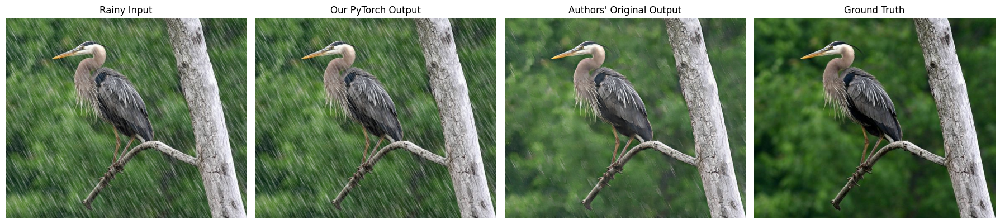

Comparison saved!


In [33]:
fig, axes = plt.subplots(1, 4, figsize=(18, 5))

for ax, (img, title) in zip(axes, comparison):
    ax.imshow(np.clip(img, 0, 1))
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
fig.savefig(output_dir + "/official_comparison.png", dpi=200)
plt.show()

print("Comparison saved!")

In [34]:
from google.colab import files

files.download(output_dir + "/official_comparison.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [35]:
from skimage.metrics import peak_signal_noise_ratio, structural_similarity
from PIL import Image
import numpy as np
import os

def evaluate_image(image_number):
    rainy = np.array(
        Image.open(f"{image_dir}/{image_number}rain.bmp").convert("RGB")
    ).astype(np.float32) / 255.0

    clean = np.array(
        Image.open(f"{image_dir}/{image_number}original.jpg").convert("RGB")
    ).astype(np.float32) / 255.0

    official = np.array(
        Image.open(f"{image_dir}/{image_number}derained.bmp").convert("RGB")
    ).astype(np.float32) / 255.0

    estimated_rain, restored = derain_image(rainy)

    return rainy, clean, official, estimated_rain, restored

In [36]:
all_results = {}

for n in range(1, 5):
    all_results[n] = evaluate_image(n)
    print(f"Image {n}: processed successfully")

Image 1: processed successfully
Image 2: processed successfully
Image 3: processed successfully
Image 4: processed successfully


In [37]:
results = []

for n, (rainy, clean, official, estimated, restored) in all_results.items():

    rainy_psnr = peak_signal_noise_ratio(clean, rainy, data_range=1.0)
    restored_psnr = peak_signal_noise_ratio(clean, restored, data_range=1.0)
    official_psnr = peak_signal_noise_ratio(clean, official, data_range=1.0)

    rainy_ssim = structural_similarity(
        clean, rainy, channel_axis=2, data_range=1.0
    )
    restored_ssim = structural_similarity(
        clean, restored, channel_axis=2, data_range=1.0
    )
    official_ssim = structural_similarity(
        clean, official, channel_axis=2, data_range=1.0
    )

    results.append({
        "Image": n,
        "Rainy PSNR": rainy_psnr,
        "Our PSNR": restored_psnr,
        "Official PSNR": official_psnr,
        "Rainy SSIM": rainy_ssim,
        "Our SSIM": restored_ssim,
        "Official SSIM": official_ssim
    })

results_df = pd.DataFrame(results)
display(results_df.round(4))

,Image,Rainy PSNR,Our PSNR,Official PSNR,Rainy SSIM,Our SSIM,Official SSIM
0,1,26.5772,27.1813,26.3130,0.7904,0.7943,0.8502
1,2,18.3723,18.6556,19.2329,0.4710,0.4728,0.7375
2,3,23.8926,24.3891,19.1569,0.8402,0.8417,0.8297
3,4,29.5826,30.5788,29.1684,0.8995,0.9018,0.9296


In [38]:
average_results = results_df.drop(columns=["Image"]).mean()

print("Average performance across 4 images:")
display(average_results.to_frame("Average").round(4))

Average performance across 4 images:


,Average
Rainy PSNR,24.6062
Our PSNR,25.2012
Official PSNR,23.4678
Rainy SSIM,0.7503
Our SSIM,0.7527
Official SSIM,0.8367


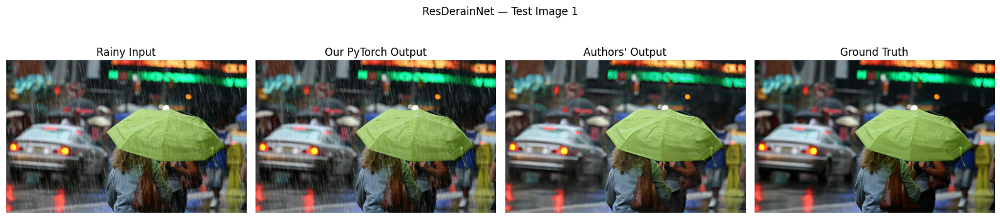

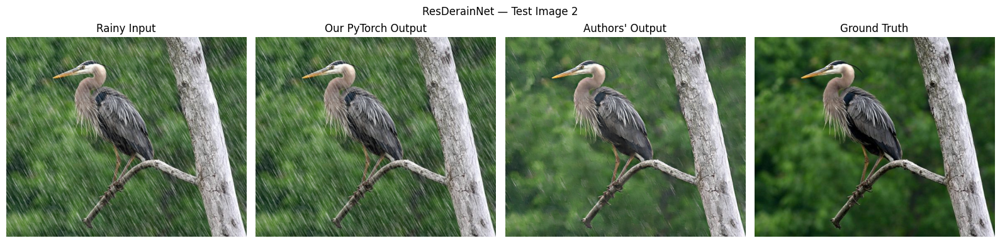

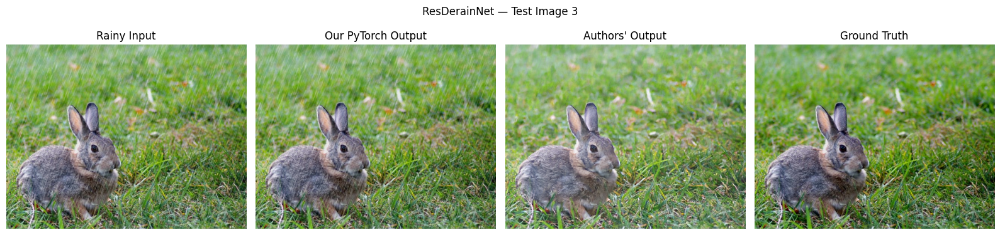

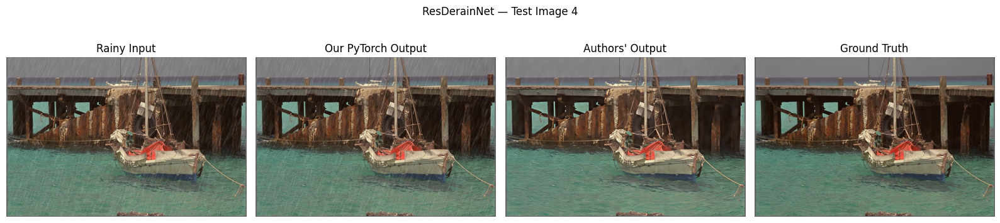

In [39]:
for n, (rainy, clean, official, estimated, restored) in all_results.items():

    fig, axes = plt.subplots(1, 4, figsize=(16, 4))

    items = [
        (rainy, "Rainy Input"),
        (restored, "Our PyTorch Output"),
        (official, "Authors' Output"),
        (clean, "Ground Truth")
    ]

    for ax, (img, title) in zip(axes, items):
        ax.imshow(np.clip(img, 0, 1))
        ax.set_title(title)
        ax.axis("off")

    plt.suptitle(f"ResDerainNet — Test Image {n}")
    plt.tight_layout()
    plt.show()

In [40]:
results_df.to_csv(
    output_dir + "/all_images_evaluation.csv",
    index=False
)

print("Evaluation table saved!")

Evaluation table saved!


In [41]:
comparison_dir = output_dir + "/comparisons"
os.makedirs(comparison_dir, exist_ok=True)

for n, (rainy, clean, official, estimated, restored) in all_results.items():

    fig, axes = plt.subplots(1, 4, figsize=(16, 4))

    for ax, (img, title) in zip(axes, [
        (rainy, "Rainy Input"),
        (restored, "Our Output"),
        (official, "Official Output"),
        (clean, "Ground Truth")
    ]):
        ax.imshow(np.clip(img, 0, 1))
        ax.set_title(title)
        ax.axis("off")

    plt.tight_layout()
    fig.savefig(f"{comparison_dir}/image_{n}.png", dpi=150)
    plt.close(fig)

print("All four comparisons saved!")

All four comparisons saved!


In [42]:
real_dir = "/content/ResDerainNet-master/image/real_world"

real_images = {}

for n in range(1, 7):
    path = f"{real_dir}/{n}.jpg"

    img = np.array(
        Image.open(path).convert("RGB")
    ).astype(np.float32) / 255.0

    real_images[n] = img

    print(f"Image {n}: {img.shape}")

Image 1: (345, 550, 3)
Image 2: (600, 800, 3)
Image 3: (509, 763, 3)
Image 4: (376, 620, 3)
Image 5: (350, 593, 3)
Image 6: (443, 640, 3)


In [43]:
real_results = {}

for n, img in real_images.items():
    estimated_rain, restored = derain_image(img)

    real_results[n] = {
        "rainy": img,
        "estimated_rain": estimated_rain,
        "restored": restored
    }

    print(f"Image {n}: deraining completed")

Image 1: deraining completed
Image 2: deraining completed
Image 3: deraining completed
Image 4: deraining completed
Image 5: deraining completed
Image 6: deraining completed


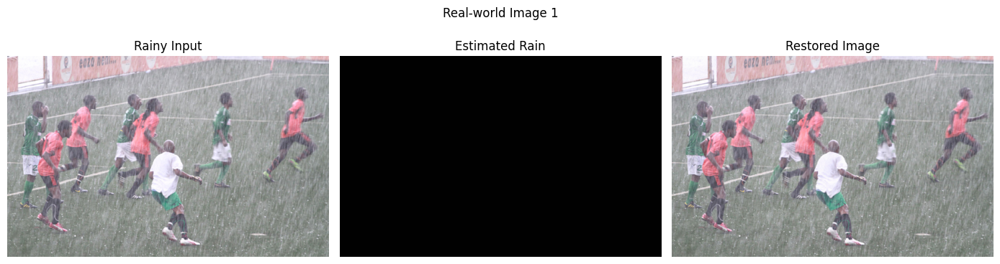

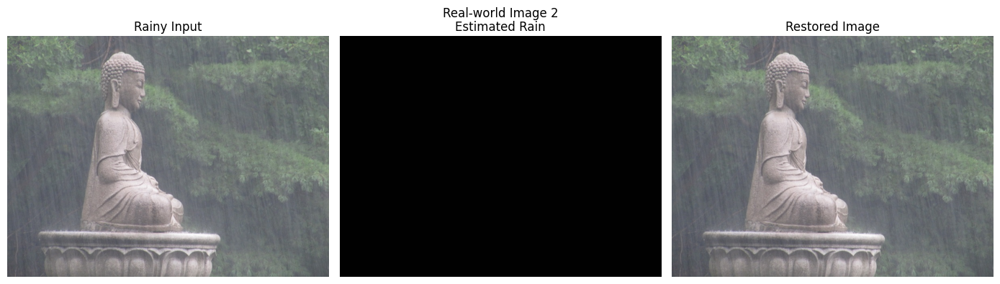

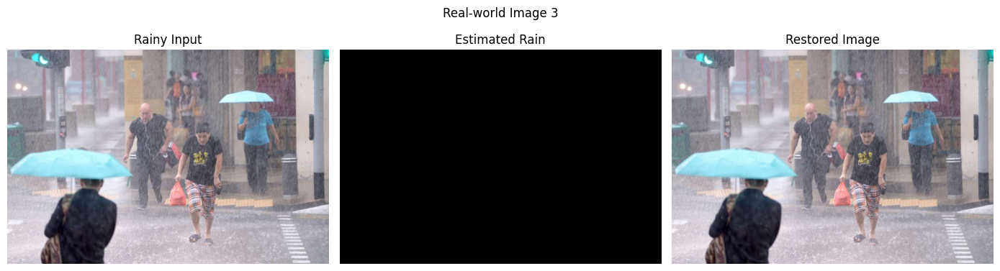

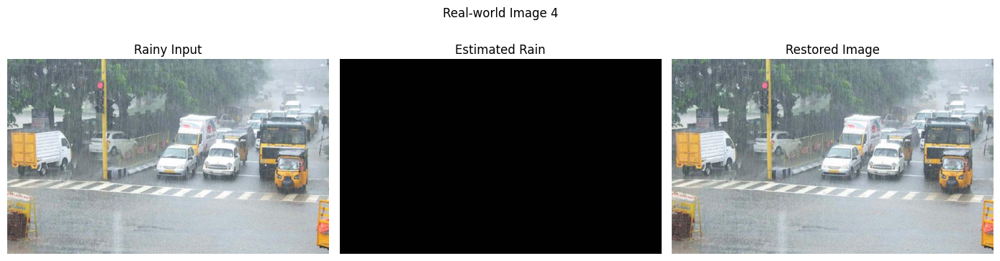

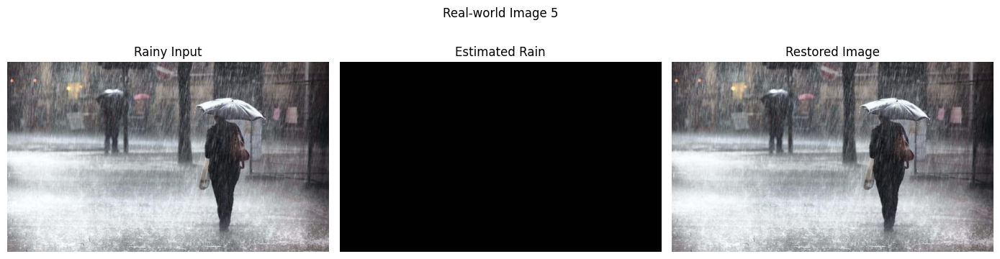

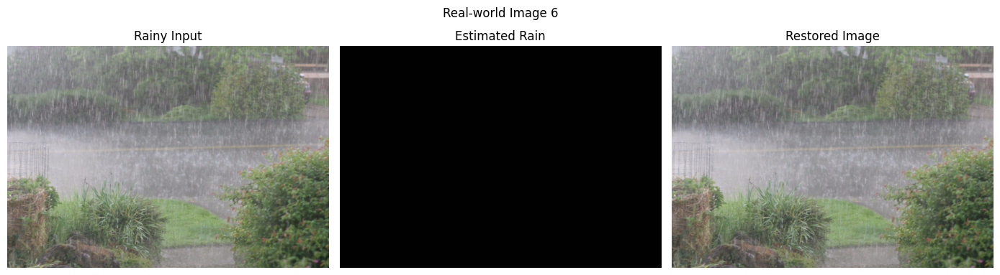

In [44]:
for n, result in real_results.items():

    fig, axes = plt.subplots(1, 3, figsize=(14, 4))

    for ax, img, title in zip(
        axes,
        [
            result["rainy"],
            result["estimated_rain"],
            result["restored"]
        ],
        ["Rainy Input", "Estimated Rain", "Restored Image"]
    ):
        ax.imshow(np.clip(img, 0, 1))
        ax.set_title(title)
        ax.axis("off")

    plt.suptitle(f"Real-world Image {n}")
    plt.tight_layout()
    plt.show()

In [45]:
real_output_dir = output_dir + "/real_world"
os.makedirs(real_output_dir, exist_ok=True)

for n, result in real_results.items():

    restored = np.clip(result["restored"], 0, 1)

    Image.fromarray(
        (restored * 255).astype(np.uint8)
    ).save(f"{real_output_dir}/restored_{n}.png")

print("All real-world restored images saved!")

All real-world restored images saved!


In [46]:
import shutil

shutil.make_archive(
    "/content/ResDerainNet_Final_Results",
    "zip",
    output_dir
)

print("Results ZIP created successfully!")

Results ZIP created successfully!


In [47]:
from google.colab import files

files.download("/content/ResDerainNet_Final_Results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [48]:
from google.colab import files
files.download("/content/ResDerainNet_Final_Results.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [49]:
files.download("/content/ResDerainNet_pytorch.pth")

FileNotFoundError: Cannot find file: /content/ResDerainNet_pytorch.pth

In [50]:
import os
import torch

checkpoint_path = "/content/ResDerainNet_pytorch.pth"

torch.save(model.state_dict(), checkpoint_path)

if os.path.exists(checkpoint_path):
    print("Checkpoint saved successfully!")
    print("File size:", round(os.path.getsize(checkpoint_path) / (1024**2), 2), "MB")
else:
    print("Checkpoint save failed!")

Checkpoint saved successfully!
File size: 2.61 MB


In [51]:
from google.colab import files

files.download("/content/ResDerainNet_pytorch.pth")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [52]:
results_df.to_csv(
    "/content/ResDerainNet_evaluation.csv",
    index=False
)
print("Evaluation saved!")

Evaluation saved!


In [53]:
average_results.to_csv(
    "/content/ResDerainNet_average_metrics.csv",
    header=["Average"]
)
print("Average metrics saved!")

Average metrics saved!


In [54]:
with open("/content/ResDerainNet_architecture.txt", "w") as f:
    f.write(str(model))

print("Architecture saved!")

Architecture saved!


In [55]:
from google.colab import files

files.download("/content/ResDerainNet_evaluation.csv")
files.download("/content/ResDerainNet_average_metrics.csv")
files.download("/content/ResDerainNet_architecture.txt")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [56]:

from skimage.metrics import peak_signal_noise_ratio, structural_similarity
import numpy as np
import pandas as pd
from PIL import Image
import os

validation_results = []

for n in range(1, 5):

    rainy, clean, official, estimated, restored = all_results[n]

    # Reconstruct exactly as the MATLAB demo does:
    # final_output = rainy_image - mid_output
    raw_output = rainy - estimated

    # Evaluate both clipped and unclipped outputs
    raw_psnr = peak_signal_noise_ratio(
        clean, raw_output, data_range=1.0
    )
    clipped_psnr = peak_signal_noise_ratio(
        clean, np.clip(raw_output, 0, 1), data_range=1.0
    )
    official_psnr = peak_signal_noise_ratio(
        clean, official, data_range=1.0
    )

    raw_ssim = structural_similarity(
        clean, raw_output,
        channel_axis=2, data_range=1.0
    )
    clipped_ssim = structural_similarity(
        clean, np.clip(raw_output, 0, 1),
        channel_axis=2, data_range=1.0
    )
    official_ssim = structural_similarity(
        clean, official,
        channel_axis=2, data_range=1.0
    )

    mae = np.mean(np.abs(raw_output - official))

    validation_results.append({
        "Image": n,
        "Raw PSNR": raw_psnr,
        "Clipped PSNR": clipped_psnr,
        "Official PSNR": official_psnr,
        "Raw SSIM": raw_ssim,
        "Clipped SSIM": clipped_ssim,
        "Official SSIM": official_ssim,
        "MAE vs Official": mae
    })

validation_df = pd.DataFrame(validation_results)

print("FINAL VALIDATION — ALL FOUR SYNTHETIC IMAGES")
display(validation_df.round(4))

print("\nAverage metrics:")
display(validation_df.drop(columns=["Image"]).mean().to_frame("Average").round(4))

print("\nPixel range of raw PyTorch outputs:")
for n, (rainy, clean, official, estimated, restored) in all_results.items():
    raw = rainy - estimated
    print(
        f"Image {n}: min={raw.min():.5f}, "
        f"max={raw.max():.5f}"
    )

validation_df.to_csv(
    "/content/ResDerainNet_final_validation.csv",
    index=False
)

print("\nValidation report saved!")


FINAL VALIDATION — ALL FOUR SYNTHETIC IMAGES


,Image,Raw PSNR,Clipped PSNR,Official PSNR,Raw SSIM,Clipped SSIM,Official SSIM,MAE vs Official
0,1,27.1812,27.1813,26.3130,0.7943,0.7943,0.8502,0.0266
1,2,18.6556,18.6556,19.2329,0.4728,0.4728,0.7375,0.0381
2,3,24.3891,24.3891,19.1569,0.8417,0.8417,0.8297,0.0650
3,4,30.5788,30.5788,29.1684,0.9018,0.9018,0.9296,0.0177



Average metrics:


,Average
Raw PSNR,25.2012
Clipped PSNR,25.2012
Official PSNR,23.4678
Raw SSIM,0.7527
Clipped SSIM,0.7527
Official SSIM,0.8367
MAE vs Official,0.0369



Pixel range of raw PyTorch outputs:
Image 1: min=-0.00483, max=0.99531
Image 2: min=-0.00482, max=0.99532
Image 3: min=-0.00483, max=0.99523
Image 4: min=-0.00482, max=0.99529

Validation report saved!


In [57]:
import os
import shutil
import json
import torch
import pandas as pd

base = "/content/ResDerainNet_Submission"
os.makedirs(base, exist_ok=True)

# 1. Save pretrained PyTorch model
torch.save(model.state_dict(), f"{base}/ResDerainNet_pytorch.pth")

# 2. Save evaluation reports
results_df.to_csv(f"{base}/synthetic_evaluation.csv", index=False)
validation_df.to_csv(f"{base}/final_validation.csv", index=False)

# 3. Save average metrics
average_results.to_csv(f"{base}/average_metrics.csv", header=["Average"])

# 4. Save architecture
with open(f"{base}/architecture.txt", "w") as f:
    f.write(str(model))

# 5. Copy generated comparison images
if os.path.exists(comparison_dir):
    shutil.copytree(
        comparison_dir,
        f"{base}/synthetic_comparisons",
        dirs_exist_ok=True
    )

# 6. Copy real-world restored images
if os.path.exists(real_output_dir):
    shutil.copytree(
        real_output_dir,
        f"{base}/real_world_results",
        dirs_exist_ok=True
    )

# 7. Add project information
info = {
    "Project": "Single-Image Rain Removal Using Residual Deep Learning",
    "Paper": "IEEE ICIP 2018",
    "Framework": "PyTorch",
    "Hardware": torch.cuda.get_device_name(0),
    "Architecture": "20 convolution layers",
    "Pretrained_weights": "Original authors' Caffe checkpoint converted to PyTorch",
    "Training_from_scratch": False,
    "Evaluation_images": 4
}

with open(f"{base}/project_info.json", "w") as f:
    json.dump(info, f, indent=4)

# 8. Create ZIP
shutil.make_archive(
    "/content/ResDerainNet_Group29_Submission",
    "zip",
    base
)

print("Submission package created!")
print("Files included:")
for root, dirs, files_list in os.walk(base):
    for name in files_list:
        print(os.path.relpath(os.path.join(root, name), base))

from google.colab import files
files.download("/content/ResDerainNet_Group29_Submission.zip")

Submission package created!
Files included:
synthetic_evaluation.csv
final_validation.csv
average_metrics.csv
project_info.json
ResDerainNet_pytorch.pth
architecture.txt
synthetic_comparisons/image_4.png
synthetic_comparisons/image_1.png
synthetic_comparisons/image_3.png
synthetic_comparisons/image_2.png
real_world_results/restored_1.png
real_world_results/restored_4.png
real_world_results/restored_2.png
real_world_results/restored_6.png
real_world_results/restored_3.png
real_world_results/restored_5.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>